In [3]:
from pathlib import Path
import json

# Start from the notebook folder: .../evaluation/results
base_dir = Path.cwd()

# Try the folder name from your request first, then fall back to similar existing folders.
candidate_dirs = [
    base_dir / "2026-07-21-11",
    base_dir / "2026-07-21_12-11",
]

summary_path = None
for folder in candidate_dirs:
    p = folder / "summary.json"
    if p.exists():
        summary_path = p
        break

if summary_path is None:
    matches = sorted(base_dir.glob("2026-07-21*/summary.json"))
    if not matches:
        raise FileNotFoundError(
            f"Could not find summary.json in {base_dir} under folders starting with 2026-07-21"
        )
    summary_path = matches[0]

with summary_path.open("r", encoding="utf-8") as f:
    summary = json.load(f)

print(f"Loaded: {summary_path}")
summary

Loaded: c:\Users\VAS1UL\Master Thesis\DC-Avaialable Baseversion\dc-available\evaluation\results\2026-07-21_12-11\summary.json


{'faithfulness': 0.884,
 'answer_relevancy': 0.924,
 'context_precision': 0.4227,
 'answer_correctness': 0.2114,
 'num_samples': 17,
 'num_skipped': 0}

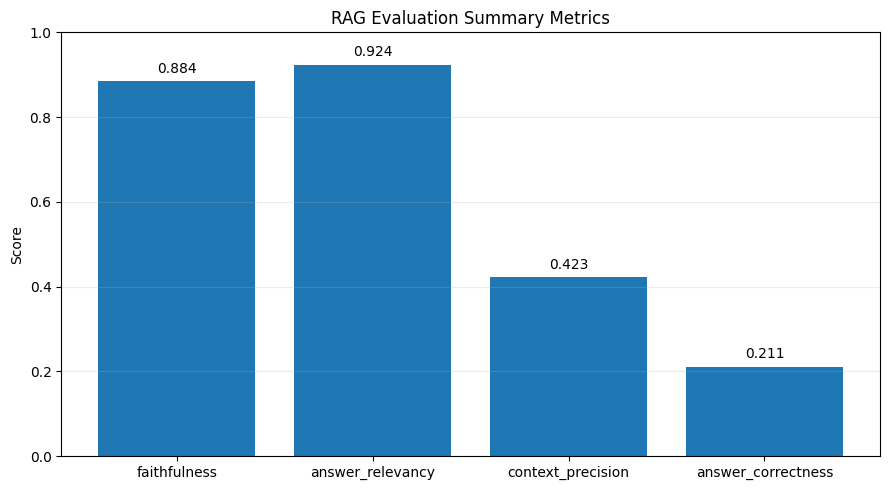

num_samples: 17 | num_skipped: 0


In [4]:
import matplotlib.pyplot as plt

# Keep only evaluation metrics for plotting.
metric_keys = [
    "faithfulness",
    "answer_relevancy",
    "context_precision",
    "answer_correctness",
]

plot_data = {k: summary[k] for k in metric_keys if k in summary}

if not plot_data:
    raise ValueError("No expected metric keys found in summary.json")

names = list(plot_data.keys())
values = list(plot_data.values())

plt.figure(figsize=(9, 5))
bars = plt.bar(names, values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("RAG Evaluation Summary Metrics")
plt.grid(axis="y", alpha=0.25)

# Add value labels above bars.
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")

plt.tight_layout()
plt.show()

print(f"num_samples: {summary.get('num_samples')} | num_skipped: {summary.get('num_skipped')}")

In [10]:
from pathlib import Path
import json
import re
import pandas as pd
import numpy as np

# ── Data Preparation ──────────────────────────────────────────────────────────
results_dir = Path.cwd()
qa_dir = results_dir / "2026-07-21_11-52" / "qa_intermediate"

candidate_files = [
    qa_dir / "qa_intermediate.json",
    qa_dir / "qa_intermidiate.json",
]

qa_json_path = None
for candidate in candidate_files:
    if candidate.exists():
        qa_json_path = candidate
        break

if qa_json_path is None:
    matches = sorted(qa_dir.glob("qa_*inter*.*json"))
    if not matches:
        raise FileNotFoundError(f"Could not find QA intermediate json in {qa_dir}")
    qa_json_path = matches[0]

with qa_json_path.open("r", encoding="utf-8") as f:
    qa_records = json.load(f)

module_pattern = re.compile(r"[A-Z0-9]{2,4}-\d{2}\.\d{3}")


def extract_modules_from_text(text: str) -> set:
    if not text or text.strip().lower() == "none":
        return set()
    return set(module_pattern.findall(text.upper()))


def extract_modules_from_retrieved(paths: list) -> set:
    modules = set()
    for p in paths or []:
        modules.update(extract_modules_from_text(str(p)))
    return modules


def parse_wrong_modules(raw: str) -> set:
    """Parse comma-separated incorrect_recommendation string."""
    if not raw or raw.strip().lower() == "none":
        return set()
    parts = [x.strip().upper() for x in raw.split(",")]
    return set(m for m in parts if module_pattern.fullmatch(m))


def safe_div(a: float, b: float) -> float:
    return a / b if b > 0 else 0.0


rows = []
for i, rec in enumerate(qa_records):
    golden_raw    = str(rec.get("golden_source", ""))
    retrieved_raw = rec.get("retrieved_source", [])
    wrong_raw     = str(rec.get("incorrect_recommendation", ""))

    G = extract_modules_from_text(golden_raw)           # ground-truth modules
    R = extract_modules_from_retrieved(retrieved_raw)   # retrieved modules
    W = parse_wrong_modules(wrong_raw)                  # flagged as wrong

    matched   = G & R
    true_wrong = R - G                                  # retrieved but NOT golden

    # ── Retrieval status ──────────────────────────────────────────────────────
    if G and G.issubset(R):
        status = "correct"
    elif matched:
        status = "partial"
    else:
        status = "incorrect"

    # ── Core retrieval metrics ────────────────────────────────────────────────
    recall      = safe_div(len(matched), len(G))
    precision   = safe_div(len(matched), len(R))
    f1          = safe_div(2 * precision * recall, precision + recall)
    exact_match = int(bool(G) and G == R)

    # ── Wrong-source metrics ──────────────────────────────────────────────────
    W_correct = W & true_wrong   # correctly flagged wrong sources
    W_fa      = W & G            # wrongly flagged correct sources

    wrong_precision  = safe_div(len(W_correct), len(W))
    wrong_recall     = safe_div(len(W_correct), len(true_wrong))
    false_alarm_rate = safe_div(len(W_fa),      len(W))
    residual_noise   = safe_div(len(true_wrong - W), len(true_wrong))

    rows.append({
        "idx":                   i,
        "question":              rec.get("question", ""),
        "golden_modules":        sorted(G),
        "retrieved_modules":     sorted(R),
        "matched_modules":       sorted(matched),
        "wrong_modules":         sorted(W),
        "true_wrong_modules":    sorted(true_wrong),
        "total_golden":          len(G),
        "total_retrieved":       len(R),
        "matched_count":         len(matched),
        "wrong_flagged":         len(W),
        "true_wrong_count":      len(true_wrong),
        "status":                status,
        "recall":                recall,
        "precision":             precision,
        "f1":                    f1,
        "exact_match":           exact_match,
        "wrong_precision":       wrong_precision,
        "wrong_recall":          wrong_recall,
        "false_alarm_rate":      false_alarm_rate,
        "residual_noise":        residual_noise,
    })

df_qa = pd.DataFrame(rows)
print(f"Loaded  : {qa_json_path}")
print(f"Records : {len(df_qa)}")
df_qa[[
    "idx", "question", "golden_modules", "wrong_modules",
    "status", "recall", "precision", "f1", "exact_match",
    "wrong_precision", "wrong_recall", "false_alarm_rate", "residual_noise"
]].head(8)

Loaded  : c:\Users\VAS1UL\Master Thesis\DC-Avaialable Baseversion\dc-available\evaluation\results\2026-07-21_11-52\qa_intermediate\qa_intermediate.json
Records : 17


,idx,question,golden_modules,wrong_modules,status,recall,precision,f1,exact_match,wrong_precision,wrong_recall,false_alarm_rate,residual_noise
0,0,Which transaction should be used for creating ...,[O2C-02.010],"[O2C-00.002, R2S-05.010]",incorrect,0.0,0.000000,0.000000,0,1.0,0.285714,0.0,0.714286
1,1,What are the existing order types for sales or...,"[O2C-00.010, O2C-02.010]",[O2C-00.002],partial,0.5,0.250000,0.333333,0,1.0,0.333333,0.0,0.666667
2,2,What is the primary purpose of the Usage Decis...,[P2P-04.010],[],correct,1.0,0.333333,0.500000,0,0.0,0.000000,0.0,1.000000
3,3,How to do a Usage Decision (UD) in SAP S/4HANA?,[P2P-04.010],[],correct,1.0,0.200000,0.333333,0,0.0,0.000000,0.0,1.000000
4,4,Which prerequisites are needed to create autom...,[P2P-04.010],[],correct,1.0,0.333333,0.500000,0,0.0,0.000000,0.0,1.000000
5,5,What billing types are existing in SAP S/4HANA?,[O2C-04.000],"[O2C-03.036, R2S-06.010]",incorrect,0.0,0.000000,0.000000,0,1.0,0.333333,0.0,0.666667
6,6,What is the process for managing a credit memo...,[O2C-04.020],[],correct,1.0,0.200000,0.333333,0,0.0,0.000000,0.0,1.000000
7,7,How does the standard outbound process looks l...,"[O2C-03.001, O2C-03.010]","[Q2E-02.020, Q2E-02.050]",partial,0.5,0.166667,0.250000,0,1.0,0.400000,0.0,0.600000


status
correct      9
partial      4
incorrect    4
Name: num_questions, dtype: int64

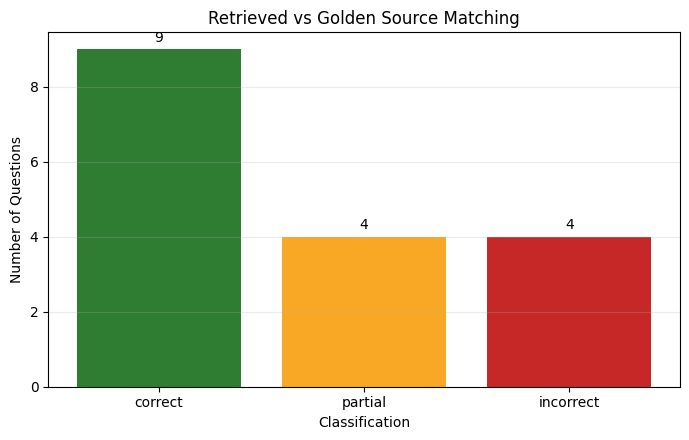

,idx,question,golden_modules,retrieved_modules,matched_modules,status
0,0,Which transaction should be used for creating ...,[O2C-02.010],"[I2O-02.010, O2C-00.002, O2C-02.021, O2C-02.02...",[],incorrect
1,1,What are the existing order types for sales or...,"[O2C-00.010, O2C-02.010]","[I2O-02.010, O2C-00.001, O2C-00.002, O2C-02.010]",[O2C-02.010],partial
5,5,What billing types are existing in SAP S/4HANA?,[O2C-04.000],"[O2C-00.004, O2C-03.036, O2C-04.013, R2S-06.01...",[],incorrect
7,7,How does the standard outbound process looks l...,"[O2C-03.001, O2C-03.010]","[O2C-03.010, O2C-03.036, P2P-03.010, P2P-04.01...",[O2C-03.010],partial
11,11,How to post a Goods Receipt in SAP S/4HANA?,"[P2P-03.010, P2P-03.011, STI-03.011]","[P2P-03.010, STI-05.020]",[P2P-03.010],partial
12,12,How to create a packaging instruction in SAP S...,"[P2P-03.012, P2P-03.013, P2P-03.014]","[O2C-03.020, O2C-03.022, O2C-03.040, O2C-03.04...",[P2P-03.012],partial
15,15,How to create a Service Order in SAP S/4HANA?,[R2S-02.000],"[O2C-03.036, R2S-01.000, R2S-02.110, R2S-06.02...",[],incorrect
16,16,How to complete Service Requests and Orders in...,[R2S-04.000],"[O2C-03.036, P2P-03.010, R2S-01.000, R2S-02.11...",[],incorrect


In [8]:
import matplotlib.pyplot as plt

# Part 2: Aggregate and plot retrieval quality counts.
status_order = ["correct", "partial", "incorrect"]
status_counts = df_qa["status"].value_counts().reindex(status_order, fill_value=0)

display(status_counts.rename("num_questions"))

plt.figure(figsize=(7, 4.5))
colors = ["#2e7d32", "#f9a825", "#c62828"]
bars = plt.bar(status_counts.index, status_counts.values, color=colors)

plt.title("Retrieved vs Golden Source Matching")
plt.xlabel("Classification")
plt.ylabel("Number of Questions")
plt.grid(axis="y", alpha=0.25)

for bar, v in zip(bars, status_counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.2, str(int(v)), ha="center")

plt.tight_layout()
plt.show()

# Optional: inspect only non-correct cases
df_qa[df_qa["status"] != "correct"][["idx", "question", "golden_modules", "retrieved_modules", "matched_modules", "status"]].head(20)

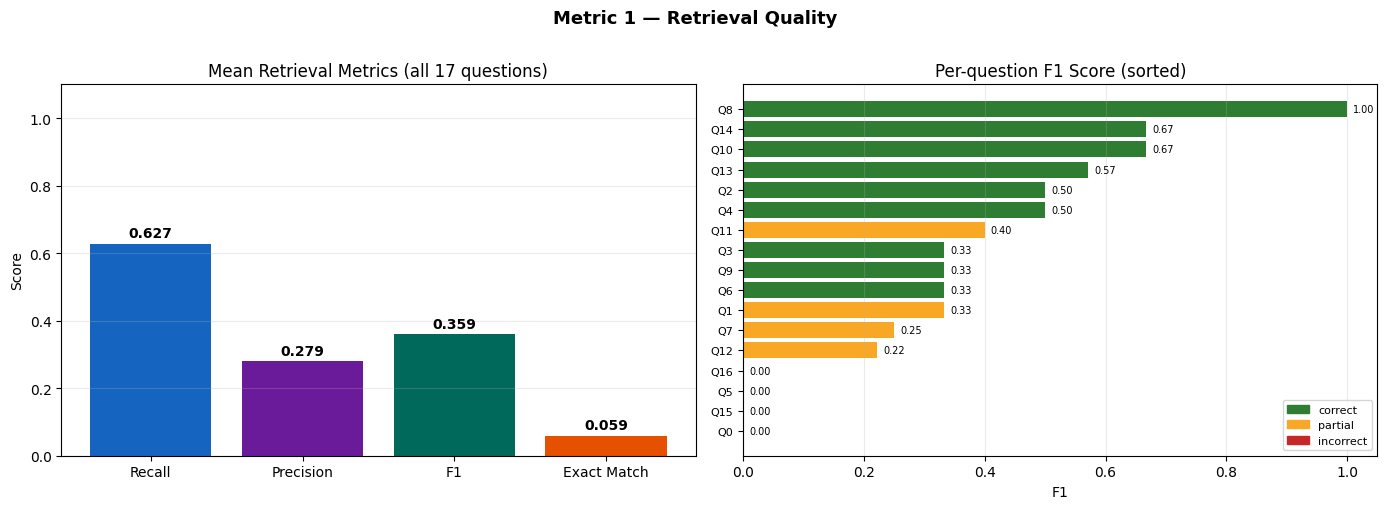

── Metric 1 Summary ──────────────────────────────────────────────────


,Metric,Mean Score,Description
0,Recall,0.627,Fraction of golden modules found in retrieved ...
1,Precision,0.279,Fraction of retrieved modules that are golden ...
2,F1,0.359,Harmonic mean of Recall & Precision
3,Exact Match,0.059,Questions where retrieved set == golden set ex...


In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ── Metric 1: Recall · Precision · F1 · Exact Match ──────────────────────────
means        = df_qa[["recall", "precision", "f1"]].mean()
exact_rate   = df_qa["exact_match"].mean()

metric_labels = ["Recall", "Precision", "F1", "Exact Match"]
metric_values = [means["recall"], means["precision"], means["f1"], exact_rate]
metric_colors = ["#1565c0", "#6a1b9a", "#00695c", "#e65100"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ─ Left: Mean metric bar chart ────────────────────────────────────────────────
bars = axes[0].bar(metric_labels, metric_values, color=metric_colors)
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Mean Retrieval Metrics (all 17 questions)")
axes[0].set_ylabel("Score")
axes[0].grid(axis="y", alpha=0.25)
for bar, v in zip(bars, metric_values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, v + 0.02,
        f"{v:.3f}", ha="center", fontsize=10, fontweight="bold"
    )

# ─ Right: Per-question F1 horizontal bar ──────────────────────────────────────
sorted_df    = df_qa.sort_values("f1", ascending=True).reset_index(drop=True)
status_color = {"correct": "#2e7d32", "partial": "#f9a825", "incorrect": "#c62828"}
q_colors     = [status_color[s] for s in sorted_df["status"]]

axes[1].barh(range(len(sorted_df)), sorted_df["f1"], color=q_colors)
axes[1].set_yticks(range(len(sorted_df)))
axes[1].set_yticklabels([f"Q{row.idx}" for _, row in sorted_df.iterrows()], fontsize=8)
axes[1].set_xlim(0, 1.05)
axes[1].set_title("Per-question F1 Score (sorted)")
axes[1].set_xlabel("F1")
axes[1].grid(axis="x", alpha=0.25)
for j, (_, row) in enumerate(sorted_df.iterrows()):
    axes[1].text(row["f1"] + 0.01, j, f"{row['f1']:.2f}", va="center", fontsize=7)

legend_els = [Patch(color=c, label=l) for l, c in status_color.items()]
axes[1].legend(handles=legend_els, loc="lower right", fontsize=8)

plt.suptitle("Metric 1 — Retrieval Quality", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# ─ Summary table ──────────────────────────────────────────────────────────────
print("── Metric 1 Summary ──────────────────────────────────────────────────")
summary_m1 = pd.DataFrame({
    "Metric":      metric_labels,
    "Mean Score":  [f"{v:.3f}" for v in metric_values],
    "Description": [
        "Fraction of golden modules found in retrieved (|G∩R|/|G|)",
        "Fraction of retrieved modules that are golden (|G∩R|/|R|)",
        "Harmonic mean of Recall & Precision",
        "Questions where retrieved set == golden set exactly",
    ]
})
display(summary_m1)

# Dataset

In [15]:
import json
import re
import pandas as pd
from pathlib import Path

results_dir = Path.cwd()
qa_json_path = results_dir / "2026-07-21_11-52" / "qa_intermediate" / "qa_intermediate.json"

with qa_json_path.open("r", encoding="utf-8") as f:
    qa_records = json.load(f)

module_pattern = re.compile(r"[A-Z0-9]{2,4}-\d{2}\.\d{3}")

def extract_modules_from_text(text: str) -> list:
    if not text or text.strip().lower() == "none":
        return []
    return sorted(set(module_pattern.findall(text.upper())))

def extract_modules_from_retrieved(paths: list) -> list:
    modules = set()
    for p in paths or []:
        modules.update(module_pattern.findall(str(p).upper()))
    return sorted(modules)

def parse_wrong_modules(raw: str) -> list:
    if not raw or raw.strip().lower() == "none":
        return []
    parts = [x.strip().upper() for x in raw.split(",")]
    return sorted(m for m in parts if module_pattern.fullmatch(m))

def retrieval_status(golden: list, retrieved: list) -> str:
    G, R = set(golden), set(retrieved)
    if not G:
        return "incorrect"
    if G.issubset(R):
        return "correct"
    if G & R:
        return "partial"
    return "incorrect"

rows = []
for rec in qa_records:
    golden    = extract_modules_from_text(str(rec.get("golden_source", "")))
    retrieved = extract_modules_from_retrieved(rec.get("retrieved_source", []))
    wrong     = parse_wrong_modules(str(rec.get("incorrect_recommendation", "")))

    rows.append({
        "question":          rec.get("question", ""),
        "golden_modules":    golden,
        "retrieved_modules": retrieved,
        "wrong_modules":     wrong,
        "n_golden":          len(golden),
        "n_retrieved":       len(retrieved),
        "n_wrong":           len(wrong),
        "retrieval_status":  retrieval_status(golden, retrieved),
    })

df_qa = pd.DataFrame(rows)
df_qa

,question,golden_modules,retrieved_modules,wrong_modules,n_golden,n_retrieved,n_wrong,retrieval_status
0,Which transaction should be used for creating ...,[O2C-02.010],"[I2O-02.010, O2C-00.002, O2C-02.021, O2C-02.02...","[O2C-00.002, R2S-05.010]",1,7,2,incorrect
1,What are the existing order types for sales or...,"[O2C-00.010, O2C-02.010]","[I2O-02.010, O2C-00.001, O2C-00.002, O2C-02.010]",[O2C-00.002],2,4,1,partial
2,What is the primary purpose of the Usage Decis...,[P2P-04.010],"[P2P-04.010, Q2E-01.020, Q2E-02.040]",[],1,3,0,correct
3,How to do a Usage Decision (UD) in SAP S/4HANA?,[P2P-04.010],"[O2C-02.021, P2P-04.010, P2P-04.012, Q2E-02.03...",[],1,5,0,correct
4,Which prerequisites are needed to create autom...,[P2P-04.010],"[P2P-04.010, P2P-04.011, Q2E-02.040]",[],1,3,0,correct
5,What billing types are existing in SAP S/4HANA?,[O2C-04.000],"[O2C-00.004, O2C-03.036, O2C-04.013, R2S-06.01...","[O2C-03.036, R2S-06.010]",1,6,2,incorrect
6,What is the process for managing a credit memo...,[O2C-04.020],"[O2C-02.060, O2C-04.000, O2C-04.020, O2C-04.02...",[],1,5,0,correct
7,How does the standard outbound process looks l...,"[O2C-03.001, O2C-03.010]","[O2C-03.010, O2C-03.036, P2P-03.010, P2P-04.01...","[Q2E-02.020, Q2E-02.050]",2,6,2,partial
8,How to sep up a standard sales quotation in SA...,[I2O-02.010],[I2O-02.010],[],1,1,0,correct
9,How does the purchase order approval is workin...,[S2C-03.010],"[O2C-02.010, O2C-02.022, O2C-03.021, O2C-03.03...","[O2C-02.010, O2C-02.022, O2C-03.036]",1,5,3,correct


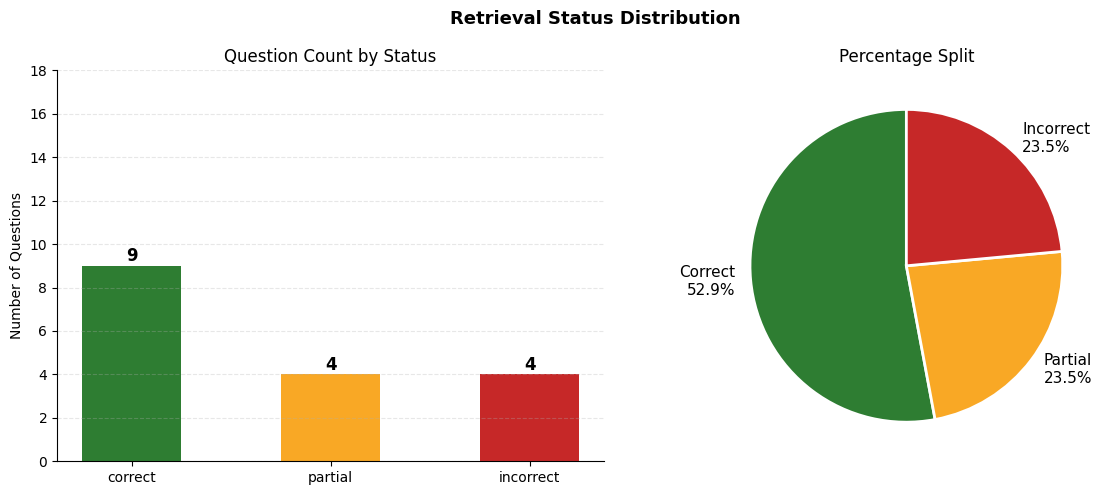

In [19]:
import matplotlib.pyplot as plt

status_order  = ["correct", "partial", "incorrect"]
status_colors = ["#2e7d32", "#f9a825", "#c62828"]

counts = df_qa["retrieval_status"].value_counts().reindex(status_order, fill_value=0)
total  = counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Retrieval Status Distribution", fontsize=13, fontweight="bold")

# ── Left: count bar chart ─────────────────────────────────────────────────────
bars = axes[0].bar(counts.index, counts.values, color=status_colors, width=0.5)
axes[0].set_title("Question Count by Status")
axes[0].set_ylabel("Number of Questions")
axes[0].set_ylim(0, total + 1)
axes[0].grid(axis="y", alpha=0.3, linestyle="--")
axes[0].spines[["top", "right"]].set_visible(False)
for bar, v in zip(bars, counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, v + 0.2,
        str(int(v)), ha="center", fontsize=12, fontweight="bold"
    )

# ── Right: percentage pie chart ───────────────────────────────────────────────
pct_labels = [f"{s.capitalize()}\n{v/total*100:.1f}%" for s, v in zip(counts.index, counts.values)]
axes[1].pie(
    counts.values,
    labels=pct_labels,
    colors=status_colors,
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)
axes[1].set_title("Percentage Split")

plt.tight_layout()
plt.show()

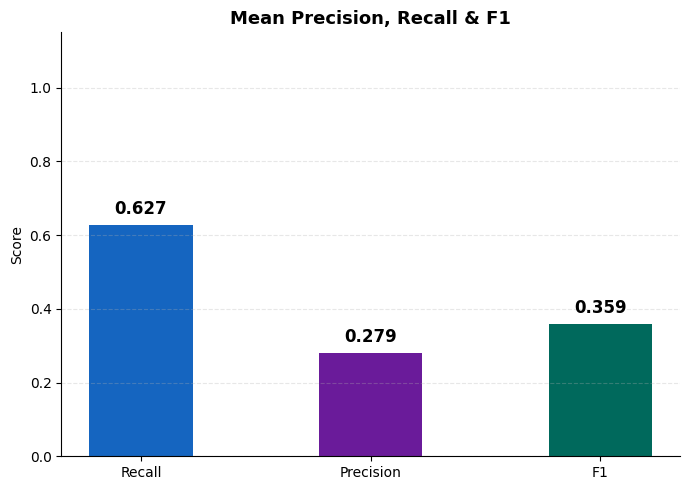

In [20]:
import matplotlib.pyplot as plt

def safe_div(a, b):
    return a / b if b > 0 else 0.0

# Compute per-question precision, recall, F1
recalls, precisions, f1s = [], [], []

for _, row in df_qa.iterrows():
    G = set(row["golden_modules"])
    R = set(row["retrieved_modules"])
    matched = G & R

    r = safe_div(len(matched), len(G))
    p = safe_div(len(matched), len(R))
    f = safe_div(2 * p * r, p + r)

    recalls.append(r)
    precisions.append(p)
    f1s.append(f)

mean_recall    = sum(recalls)    / len(recalls)
mean_precision = sum(precisions) / len(precisions)
mean_f1        = sum(f1s)        / len(f1s)

labels = ["Recall", "Precision", "F1"]
values = [mean_recall, mean_precision, mean_f1]
colors = ["#1565c0", "#6a1b9a", "#00695c"]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(labels, values, color=colors, width=0.45)
ax.set_ylim(0, 1.15)
ax.set_title("Mean Precision, Recall & F1", fontsize=13, fontweight="bold")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.spines[["top", "right"]].set_visible(False)

for bar, v in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2, v + 0.03,
        f"{v:.3f}", ha="center", fontsize=12, fontweight="bold"
    )

plt.tight_layout()
plt.show()

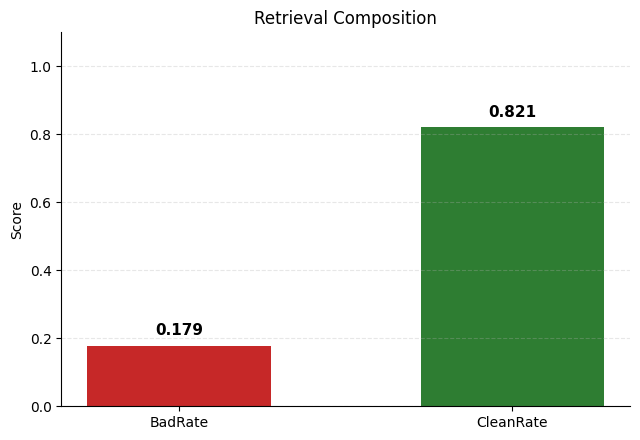

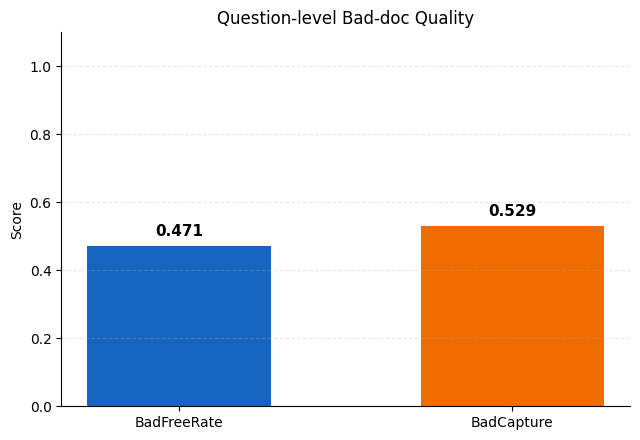

,Metric,Value,Better
0,BadRate,0.179,Lower
1,CleanRate,0.821,Higher
2,BadFreeRate,0.471,Higher
3,BadCapture,0.529,Lower


In [25]:
import matplotlib.pyplot as plt
import pandas as pd

def safe_div(a, b):
    return a / b if b > 0 else 0.0

def to_set(x):
    if isinstance(x, list):
        return set(str(v).upper().strip() for v in x if str(v).strip())
    if isinstance(x, str):
        if x.strip().lower() == "none" or not x.strip():
            return set()
        return set(v.strip().upper() for v in x.split(",") if v.strip())
    return set()

# Compute bad-document metrics per question
bad_rate_list, clean_rate_list, bad_free_list, bad_capture_list = [], [], [], []

for _, row in df_qa.iterrows():
    R = to_set(row["retrieved_modules"])
    B = to_set(row["wrong_modules"])  # incorrect_recommendation

    bad_retrieved = R & B

    bad_rate = safe_div(len(bad_retrieved), len(R))         # lower better
    clean_rate = 1 - bad_rate                               # higher better
    bad_free = 1.0 if len(bad_retrieved) == 0 else 0.0      # higher better
    bad_capture = safe_div(len(bad_retrieved), len(B))      # lower better

    bad_rate_list.append(bad_rate)
    clean_rate_list.append(clean_rate)
    bad_free_list.append(bad_free)
    bad_capture_list.append(bad_capture)

# Dataset means
bad_rate_mean = sum(bad_rate_list) / len(bad_rate_list)
clean_rate_mean = sum(clean_rate_list) / len(clean_rate_list)
bad_free_mean = sum(bad_free_list) / len(bad_free_list)
bad_capture_mean = sum(bad_capture_list) / len(bad_capture_list)

# -------- Plot A: Composition --------
labels_a = ["BadRate", "CleanRate"]
values_a = [bad_rate_mean, clean_rate_mean]
colors_a = ["#c62828", "#2e7d32"]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(labels_a, values_a, color=colors_a, width=0.55)
ax.set_ylim(0, 1.1)
ax.set_title("Retrieval Composition")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.spines[["top", "right"]].set_visible(False)

for bar, v in zip(bars, values_a):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.03, f"{v:.3f}",
            ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

# -------- Plot B: Question-level Quality --------
labels_b = ["BadFreeRate", "BadCapture"]
values_b = [bad_free_mean, bad_capture_mean]
colors_b = ["#1565c0", "#ef6c00"]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(labels_b, values_b, color=colors_b, width=0.55)
ax.set_ylim(0, 1.1)
ax.set_title("Question-level Bad-doc Quality")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.spines[["top", "right"]].set_visible(False)

for bar, v in zip(bars, values_b):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.03, f"{v:.3f}",
            ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

# Optional table
pd.DataFrame({
    "Metric": ["BadRate", "CleanRate", "BadFreeRate", "BadCapture"],
    "Value": [round(bad_rate_mean, 3), round(clean_rate_mean, 3),
              round(bad_free_mean, 3), round(bad_capture_mean, 3)],
    "Better": ["Lower", "Higher", "Higher", "Lower"]
})